# Gem Cutting Pattern Recommendation Model

Classifies a gem image (gem type + rough/cut state) and maps it to a recommended cutting pattern.

In [1]:
from __future__ import annotations

import json
import random
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import tensorflow as tf
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from PIL import Image

def _project_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / "backend").exists() and (candidate / "ml").exists():
            return candidate
    return start

ROOT = _project_root(Path.cwd())
ML_DIR = ROOT / "ml" / "gem-pattern-recommendation"
DATASET = ML_DIR / "dataset"
BACKEND = ROOT / "backend"
MODEL_OUT = BACKEND / "models" / "gem_pattern_model.keras"
LABELS_OUT = BACKEND / "models" / "labels.json"

IMG_SIZE = (224, 224)
BATCH_SIZE = 16
SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)
print("ROOT:", ROOT)


I0000 00:00:1792325457.579688  534297 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792325457.580989  534297 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792325457.817007  534297 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792325463.957338  534297 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

ROOT: /home/anuk/Documents/cut/GemVision


In [2]:
# If no real data is present, generate a small synthetic dataset so training runs end to end.
image_files = list(DATASET.rglob("*.jpg")) + list(DATASET.rglob("*.jpeg")) + list(DATASET.rglob("*.png"))
if not image_files:
    print("No images found - generating synthetic dataset")
    subprocess.run(
        [sys.executable, str(ML_DIR / "scripts" / "generate_synthetic_dataset.py"),
         "--output", str(DATASET), "--count", "16", "--seed", str(SEED)],
        check=True,
    )
    image_files = list(DATASET.rglob("*.jpg")) + list(DATASET.rglob("*.jpeg")) + list(DATASET.rglob("*.png"))
print("Total images:", len(image_files))


Total images: 128


In [3]:
# Collect (path, label) pairs. State folders: rough/ -> rough, faceted/ -> cut.
records = []
for state_dir, state in [("rough", "rough"), ("faceted", "cut")]:
    base = DATASET / state_dir
    if not base.exists():
        continue
    for class_dir in sorted(p for p in base.iterdir() if p.is_dir()):
        for img_path in sorted(class_dir.iterdir()):
            if img_path.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"}:
                records.append((str(img_path), f"{class_dir.name}_{state}"))

paths = np.array([r[0] for r in records])
labels = np.array([r[1] for r in records])
class_names = sorted(set(labels.tolist()))
label_to_index = {name: i for i, name in enumerate(class_names)}
y = np.array([label_to_index[x] for x in labels], dtype=np.int32)
print("Classes:", class_names)
print("Counts:", {name: int((labels == name).sum()) for name in class_names})


Classes: ['amethyst_cut', 'amethyst_rough', 'emerald_cut', 'emerald_rough', 'ruby_cut', 'ruby_rough', 'sapphire_cut', 'sapphire_rough']
Counts: {'amethyst_cut': 16, 'amethyst_rough': 16, 'emerald_cut': 16, 'emerald_rough': 16, 'ruby_cut': 16, 'ruby_rough': 16, 'sapphire_cut': 16, 'sapphire_rough': 16}


In [4]:
# Stratified 70/15/15 split.
X_train, X_temp, y_train, y_temp = train_test_split(
    paths, y, test_size=0.30, stratify=y, random_state=SEED
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED
)
print("Train/Val/Test:", len(X_train), len(X_val), len(X_test))


Train/Val/Test: 89 19 20


In [5]:
def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_image(image, channels=3, expand_animations=False)
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)
    return image, label

def make_dataset(x, y, training=False):
    ds = tf.data.Dataset.from_tensor_slices((x.tolist(), y.tolist()))
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    if training:
        ds = ds.shuffle(1000, seed=SEED)
    ds = ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    return ds

train_ds = make_dataset(X_train, y_train, training=True)
val_ds = make_dataset(X_val, y_val)
test_ds = make_dataset(X_test, y_test)


E0000 00:00:1792325466.263693  534297 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [6]:
# Data augmentation (training only).
data_augmentation = tf.keras.Sequential(
    [
        tf.keras.layers.RandomFlip("horizontal"),
        tf.keras.layers.RandomRotation(0.15),
        tf.keras.layers.RandomZoom(0.10),
        tf.keras.layers.RandomContrast(0.10),
    ],
    name="augmentation",
)

base_model = tf.keras.applications.MobileNetV2(
    input_shape=IMG_SIZE + (3,), include_top=False, weights="imagenet"
)
base_model.trainable = False

inputs = tf.keras.Input(shape=IMG_SIZE + (3,))
x = data_augmentation(inputs)
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
x = base_model(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dense(128, activation="relu")(x)
x = tf.keras.layers.Dropout(0.3)(x)
outputs = tf.keras.layers.Dense(len(class_names), activation="softmax")(x)
model = tf.keras.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
model.summary()


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,984 (9.24 MB)

 Trainable params: 165,000 (644.53 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [7]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True, monitor="val_accuracy"),
]
history1 = model.fit(train_ds, validation_data=val_ds, epochs=8, callbacks=callbacks)


Epoch 1/8


/home/anuk/Downloads/gem/venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


6/6 ━━━━━━━━━━━━━━━━━━━━ 25s 2s/step - accuracy: 0.1461 - loss: 2.2578 - val_accuracy: 0.2105 - val_loss: 1.8379
Epoch 2/8
6/6 ━━━━━━━━━━━━━━━━━━━━ 4s 788ms/step - accuracy: 0.2921 - loss: 1.6346 - val_accuracy: 0.4211 - val_loss: 1.5658
Epoch 3/8
6/6 ━━━━━━━━━━━━━━━━━━━━ 5s 922ms/step - accuracy: 0.5281 - loss: 1.3185 - val_accuracy: 0.3684 - val_loss: 1.2670
Epoch 4/8
6/6 ━━━━━━━━━━━━━━━━━━━━ 5s 916ms/step - accuracy: 0.5955 - loss: 1.0754 - val_accuracy: 0.4211 - val_loss: 1.2290
Epoch 5/8
6/6 ━━━━━━━━━━━━━━━━━━━━ 6s 975ms/step - accuracy: 0.6404 - loss: 1.0129 - val_accuracy: 0.4737 - val_loss: 1.1403
Epoch 6/8
6/6 ━━━━━━━━━━━━━━━━━━━━ 5s 838ms/step - accuracy: 0.6067 - loss: 0.9222 - val_accuracy: 0.4211 - val_loss: 1.2182
Epoch 7/8
6/6 ━━━━━━━━━━━━━━━━━━━━ 5s 877ms/step - accuracy: 0.6742 - loss: 0.8629 - val_accuracy: 0.4737 - val_loss: 1.1795
Epoch 8/8
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 525ms/step - accuracy: 0.7640 - loss: 0.6822 - val_accuracy: 0.4737 - val_loss: 1.1306


In [8]:
# Fine-tune the top layers of the backbone.
base_model.trainable = True
for layer in base_model.layers[:-20]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
history2 = model.fit(train_ds, validation_data=val_ds, epochs=4, callbacks=callbacks)


Epoch 1/4
6/6 ━━━━━━━━━━━━━━━━━━━━ 34s 2s/step - accuracy: 0.4719 - loss: 1.2943 - val_accuracy: 0.4211 - val_loss: 1.1328
Epoch 2/4
6/6 ━━━━━━━━━━━━━━━━━━━━ 6s 935ms/step - accuracy: 0.6292 - loss: 0.9893 - val_accuracy: 0.4211 - val_loss: 1.1498
Epoch 3/4
6/6 ━━━━━━━━━━━━━━━━━━━━ 6s 920ms/step - accuracy: 0.7528 - loss: 0.7457 - val_accuracy: 0.4211 - val_loss: 1.1500
Epoch 4/4
6/6 ━━━━━━━━━━━━━━━━━━━━ 6s 945ms/step - accuracy: 0.7640 - loss: 0.6824 - val_accuracy: 0.3684 - val_loss: 1.1056


Test loss: 1.1838  Test accuracy: 0.6000


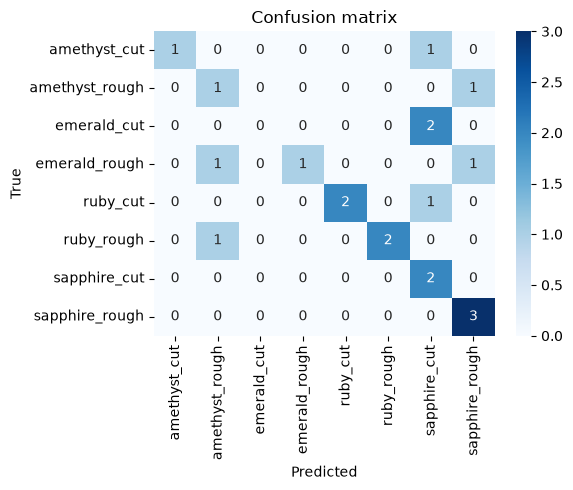

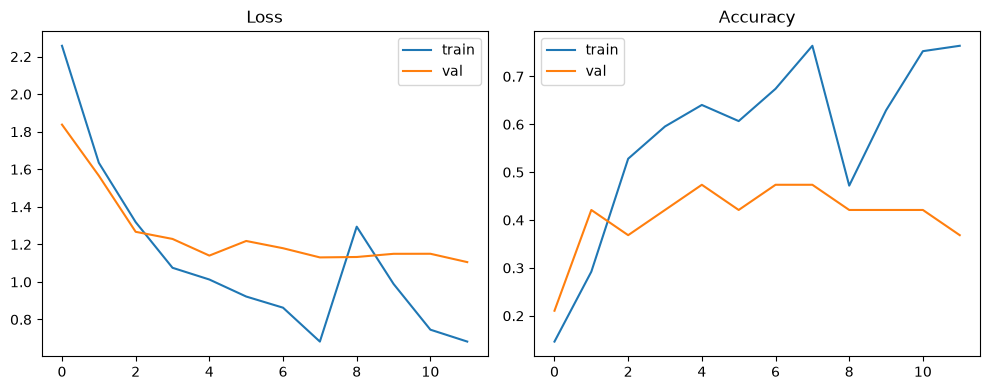

In [9]:
# Evaluation.
test_loss, test_acc = model.evaluate(test_ds, verbose=0)
print(f"Test loss: {test_loss:.4f}  Test accuracy: {test_acc:.4f}")

y_pred = np.argmax(model.predict(test_ds, verbose=0), axis=1)
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", xticklabels=class_names, yticklabels=class_names, cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion matrix")
plt.tight_layout()
plt.show()

# Loss / accuracy curves (both stages).
def _concat(key):
    return history1.history.get(key, []) + history2.history.get(key, [])

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(_concat("loss"), label="train")
plt.plot(_concat("val_loss"), label="val")
plt.title("Loss")
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(_concat("accuracy"), label="train")
plt.plot(_concat("val_accuracy"), label="val")
plt.title("Accuracy")
plt.legend()
plt.tight_layout()
plt.show()


In [10]:
# Save model and labels.
(BACKEND / "models").mkdir(parents=True, exist_ok=True)
model.save(MODEL_OUT)

labels = {
    "class_names": class_names,
    "image_size": list(IMG_SIZE),
    "backbone": "MobileNetV2",
    "recommended_pattern": "glass-shard-vortex",
}
LABELS_OUT.write_text(json.dumps(labels, indent=2), encoding="utf-8")
print("Saved:", MODEL_OUT)
print("Saved:", LABELS_OUT)


Saved: /home/anuk/Documents/cut/GemVision/backend/models/gem_pattern_model.keras
Saved: /home/anuk/Documents/cut/GemVision/backend/models/labels.json
